# Ross Sea section movie — MESACLIP piControl
Ideal age and σ2 along the Ross Sea section (77.6°S → 68.5°S),
read from the `Ross_section.zarr` written by `ross_section_compute.ipynb` (last 100 model years).
[xmovie](https://xmovie.readthedocs.io) renders the frames and the mp4.

In [1]:
import os

import cftime
import numpy as np
import xarray as xr
import xesmf
import cmocean
import cmocean.cm as cmo
from matplotlib.patches import Rectangle
from xmovie import Movie
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Video

sns.set_theme(context="notebook", style="ticks")

## Settings

In [2]:
SECTION = "../data/Ross_section.zarr"
GRID    = "/glade/u/home/ameza/MESACLIP_piControl_500year_monthly/B.E.13.B1850C5.ne120_t12.sehires38.003.sunway_02.pop.h.TEMP.015001-015912.nc"   # for the model depth HT
FRAMES  = "../data/ross_section_frames.zarr"   # interpolated frames (written below)
MOVIE   = "../plots/ross_section.mp4"

YEARS = ("0500", "0505")   # movie runs from July of the first year to July of the last
SUBFRAMES = 4              # frames per month (light linear interpolation in time)
FPS       = 3 * SUBFRAMES  # 3 months per second (4 s per model year)

BACKGROUND = "white"
SEAFLOOR   = "#6b6b66"   # mid grey
MAX_DEPTH  = 4500        # m
LAT_MAX    = -71.5       # northern end of the section

SIGMA2_LEVELS = np.arange(37.1, 37.351, 0.0125)   # plumes 37.21-37.30 vs ambient 37.15-37.24 on the slope
IAGE_LEVELS   = np.arange(50, 300.1, 12.5)       # years; plumes 136-242 vs ambient 208-296 on the slope

## Load, clean and interpolate in time (in memory)
The section is small (~90 MB per variable for 100 years), so it is loaded once and processed in memory:
- depth (m) and latitude become the coordinates; the section is cropped at `LAT_MAX` and land-only columns are dropped,
- the seafloor is the model's ocean depth `HT` along the section (smooth, drawn on top of the data),
- light linear interpolation in time: `SUBFRAMES` frames per month. No interpolation in space: `contourf` already interpolates
  linearly between grid points.

In [3]:
# POP stamps each monthly mean at the start of the next month, so July is stamped YYYY-08-01
period = slice(f"{YEARS[0]}-08-01", f"{YEARS[1]}-08-01")
raw = xr.open_zarr(SECTION)[["IAGE", "SIGMA2"]].sel(time=period).load()
raw = raw.assign_coords(depth=raw.z_t / 100).swap_dims(z_t="depth", locations="lat").drop_vars(["z_t", "lon"])
raw = raw.sel(lat=slice(None, LAT_MAX)).dropna("lat", how="all")   # crop north, drop land-only columns

# SUBFRAMES frames per month; each monthly mean sits at mid-month (15 days before its stamp) for the date label
months = np.arange(raw.sizes["time"])
frames = np.arange(0, months[-1] + 1e-9, 1 / SUBFRAMES)
units = "days since 0001-01-01"
days = np.interp(frames, months, cftime.date2num(raw.time.values, units, calendar="noleap") - 15)

# Smooth seafloor: the model's ocean depth HT (bilinear onto the section) instead of the stair-stepped depth levels.
# Same sub-box and -1 lat/lon handling as Untitled2.
grid = xr.open_dataset(GRID, decode_timedelta=True)[["HT"]].isel(nlat=slice(0, 267), nlon=slice(2800, 3200))
ok = grid.TLAT != -1
grid = grid.assign_coords(lat=grid.TLAT.where(ok), lon=grid.TLONG.where(ok))
section = xr.open_zarr(SECTION)
pts = xr.Dataset(coords={"lat": section.lat.load(), "lon": section.lon.load()})
seafloor = xesmf.Regridder(grid, pts, "bilinear", locstream_out=True, unmapped_to_nan=True)(grid.HT / 100)  # m
seafloor = seafloor.assign_coords(lat=pts.lat).swap_dims(locations="lat").sel(lat=raw.lat)

# Fill land with the nearest water value so the data reach the seafloor line (drawn on top in each frame)
filled = raw.ffill("depth").ffill("lat").bfill("lat")
ds = (filled.assign_coords(frame=("time", months)).swap_dims(time="frame").drop_vars("time")
            .interp(frame=frames)
            .assign_coords(seafloor=seafloor, time=("frame", cftime.num2date(days, units, calendar="noleap"))))

ds

<xarray.Dataset> Size: 64MB
Dimensions:   (depth: 62, lat: 267, frame: 241)
Coordinates:
  * depth     (depth) float32 248B 5.0 15.0 25.0 ... 5.625e+03 5.875e+03
  * lat       (lat) float64 2kB -77.58 -77.55 -77.53 ... -71.56 -71.53 -71.51
  * frame     (frame) float64 2kB 0.0 0.25 0.5 0.75 ... 59.25 59.5 59.75 60.0
    lon       (lat) float64 2kB 178.0 178.1 178.1 178.1 ... 186.0 186.0 186.0
    seafloor  (lat) float64 2kB 478.4 643.5 672.3 ... 3.282e+03 3.345e+03
    time      (frame) object 2kB 0500-07-17 00:00:00 ... 0505-07-17 00:00:00
Data variables:
    IAGE      (frame, depth, lat) float64 32MB 0.0 0.0 0.0 ... 212.4 212.5 216.1
    SIGMA2    (frame, depth, lat) float64 32MB 37.31 37.31 37.29 ... 37.26 37.26
Attributes:
    regrid_method:  bilinear

xmovie sends the dataset to every worker process, so rather than shipping the in-memory arrays to each frame,
write them to a zarr store with one frame per chunk and let each process read just its frame.

In [4]:
ds.astype("float32").chunk(frame=1).to_zarr(FRAMES, mode="w")
ds = xr.open_zarr(FRAMES)

/glade/work/ameza/conda-envs/cupid-analysis/lib/python3.11/site-packages/zarr/api/asynchronous.py:244: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


## Frame
xmovie calls `draw(ds, fig, tt, framedim)` for every frame `tt`. Two panels (ideal age on top, σ2 below), seafloor in grey.
xmovie saves frames with `transparent=True`, which drops figure/axes face colours, so the background and seafloor
are drawn as shapes instead. The label shows the date (e.g. February 17) and model year, like Untitled1.

In [5]:
soften = lambda cmap: cmocean.tools.crop_by_percent(cmap, 15, which="both")   # trim the darkest/lightest 15%
PANELS = [("IAGE",   cmocean.tools.crop_by_percent(soften(cmo.deep), 12, which="max"),   # lighter darkest colour
            IAGE_LEVELS,   "Ideal age", "[years]"),
          ("SIGMA2", soften(cmo.dense), SIGMA2_LEVELS, "Potential density ($\\sigma_2$)", "[kg m$^{-3}$]")]

def draw(ds, fig, tt, framedim="frame"):
    snap = ds.isel({framedim: tt}).load()
    date = snap.time.item()

    fig.add_artist(Rectangle((0, 0), 1, 1, transform=fig.transFigure, color=BACKGROUND, zorder=-1))

    ax = None
    for k, (var, cmap, levels, label, units) in enumerate(PANELS):
        ax = fig.add_axes([0.13, 0.50 - 0.395 * k, 0.68, 0.38], sharex=ax)   # shared latitude axis
        cax = fig.add_axes([0.825, 0.50 - 0.395 * k, 0.012, 0.38])
        # filled contours on the fine interpolated grid
        pm = ax.contourf(snap.lat, snap.depth, snap[var], levels=levels, cmap=cmap, extend="both")
        ax.fill_between(snap.lat, snap.seafloor, MAX_DEPTH, color=SEAFLOOR, zorder=3)   # smooth seafloor on top
        cb = fig.colorbar(pm, cax=cax, ticks=levels[::4])
        ax.text(0.01, 0.03, label, transform=ax.transAxes, color="white", fontsize=18, zorder=4)   # over the seafloor
        cb.set_label(units, fontsize=16)
        cb.ax.tick_params(labelsize=13)
        ax.set_ylim(MAX_DEPTH, 0)
        ax.set_ylabel("Depth (m)", fontsize=16)
        ax.tick_params(labelsize=13, labelbottom=(k == len(PANELS) - 1))   # latitude labels on the bottom panel only
    ax.set_xlabel("Latitude", fontsize=16)

    fig.text(0.47, 0.95, "Ross Sea section", ha="center", fontsize=24)
    fig.text(0.47, 0.935, f"Month: {date.strftime('%B')}    Model year: {date.year:04d}", ha="center", va="top", fontsize=16)
    fig.text(0.97, 0.03, "Source: MESACLIP", ha="right", fontsize=14)
    return ax, pm

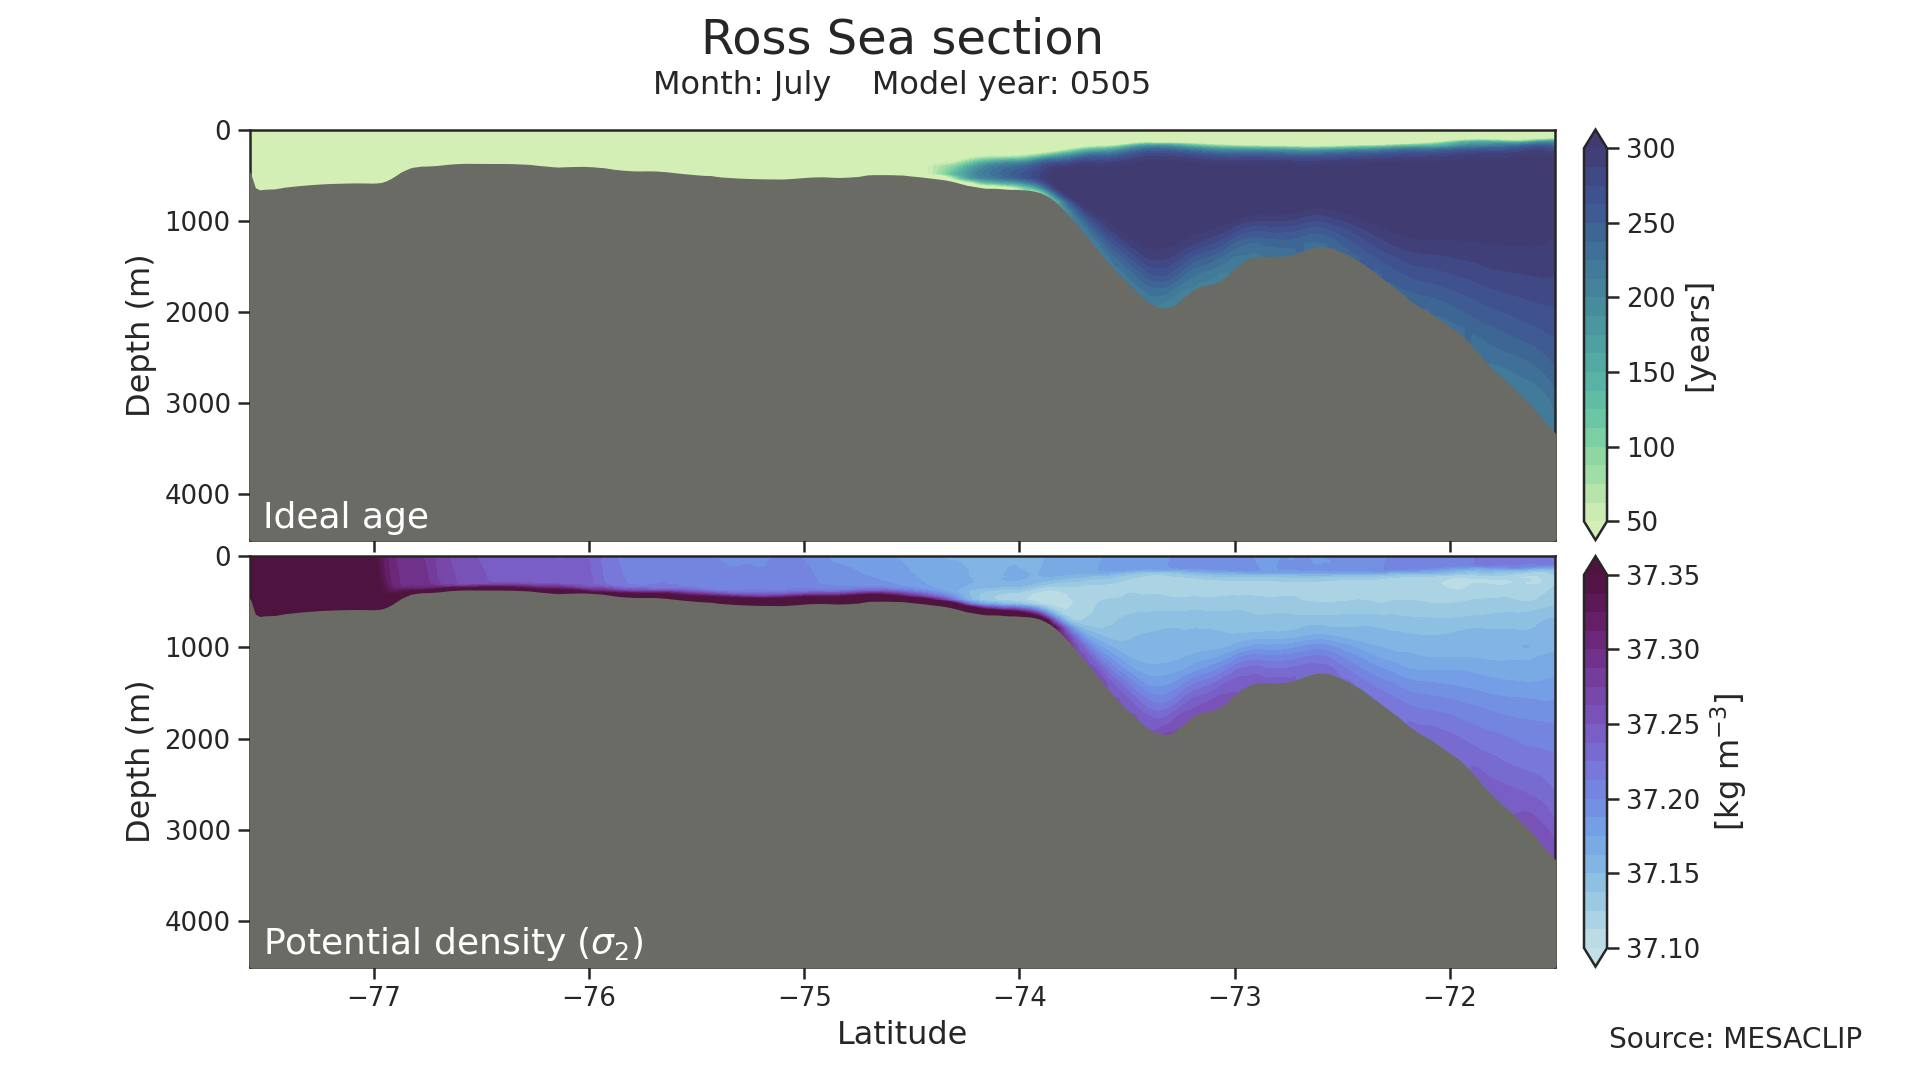

In [6]:
mov = Movie(ds, draw, framedim="frame", pixelwidth=1920, pixelheight=1080, dpi=144, input_check=False)   # 13.33 x 7.5 in: a 16:9 slide
fig, _, _ = mov.render_single_frame(ds.sizes["frame"] - 1)   # last frame
fig.savefig("../plots/ross_section_preview.png", transparent=True, dpi=mov.dpi)   # same as xmovie, so the preview matches the movie
plt.close(fig)
Image("../plots/ross_section_preview.png")

## Movie
Rendered in parallel with one process per core. 3 months per second (4 s per model year).

In [7]:
mov.save(MOVIE, parallel=True, overwrite_existing=True, framerate=FPS,
         parallel_compute_kwargs=dict(scheduler="processes", num_workers=len(os.sched_getaffinity(0))),
         ffmpeg_options="-c:v libx264 -crf 18 -pix_fmt yuv420p")

Video(MOVIE, width=960)

Movie created at ross_section.mp4
